# Exploratory Data Analysis (EDA)

This notebook performs comprehensive exploratory data analysis on the Mental Health in Tech Survey dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os

# Add src directory to path
sys.path.append(os.path.abspath('../src'))

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

# Load the dataset
data_path = '../data/survey.csv'
df = pd.read_csv(data_path)

print(f"Dataset loaded successfully!")
print(f"Shape: {df.shape}")

Dataset loaded successfully!
Shape: (1259, 27)


## Dataset Overview

In [2]:
# Display dataset shape
print(f"Dataset Shape: {df.shape}")
print(f"\nNumber of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Dataset Shape: (1259, 27)

Number of rows: 1259
Number of columns: 27


In [3]:
# Display data types
print("\nData Types:")
print(df.dtypes)


Data Types:
Timestamp                    object
Age                           int64
Gender                       object
Country                      object
state                        object
self_employed                object
family_history               object
treatment                    object
work_interfere               object
no_employees                 object
remote_work                  object
tech_company                 object
benefits                     object
care_options                 object
wellness_program             object
seek_help                    object
anonymity                    object
leave                        object
mental_health_consequence    object
phys_health_consequence      object
coworkers                    object
supervisor                   object
mental_health_interview      object
phys_health_interview        object
mental_vs_physical           object
obs_consequence              object
comments                     object
dtype: object


In [4]:
# Display missing value counts per column
print("\nMissing Values per Column:")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])
print(f"\nTotal missing values: {df.isnull().sum().sum()}")


Missing Values per Column:
state              515
self_employed       18
work_interfere     264
comments          1095
dtype: int64

Total missing values: 1892


In [5]:
# Display column names
print("\nColumn Names:")
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")


Column Names:
1. Timestamp
2. Age
3. Gender
4. Country
5. state
6. self_employed
7. family_history
8. treatment
9. work_interfere
10. no_employees
11. remote_work
12. tech_company
13. benefits
14. care_options
15. wellness_program
16. seek_help
17. anonymity
18. leave
19. mental_health_consequence
20. phys_health_consequence
21. coworkers
22. supervisor
23. mental_health_interview
24. phys_health_interview
25. mental_vs_physical
26. obs_consequence
27. comments


## Age Distribution (Before Cleaning)

Saved figure to ../outputs/figures\age_distribution_before_cleaning.png


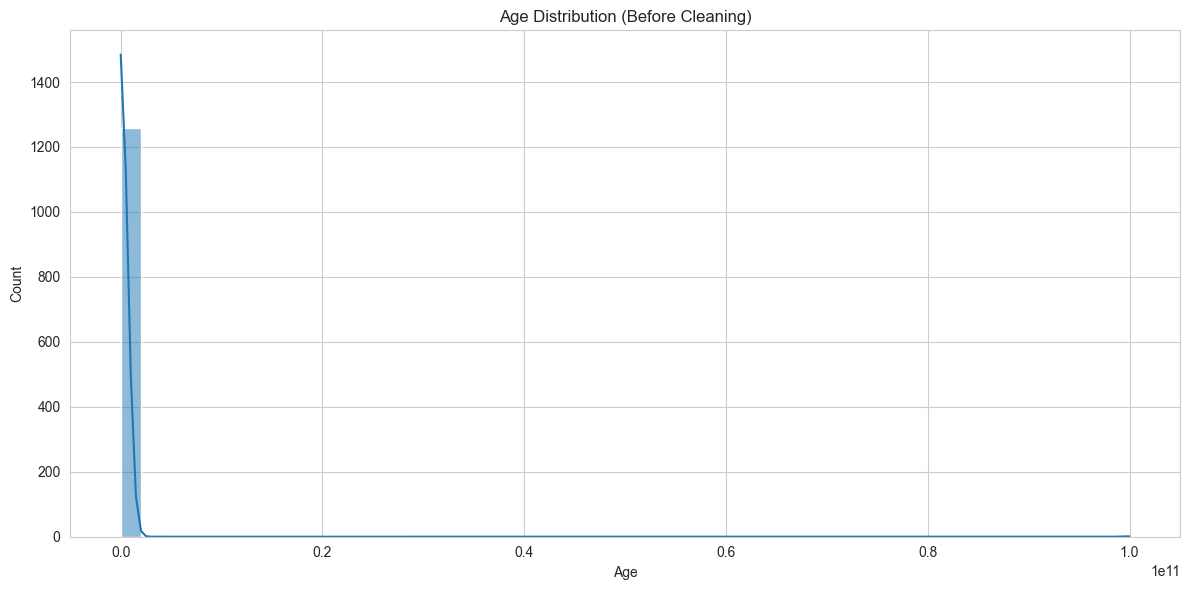

Age Statistics:
count    1.259000e+03
mean     7.942815e+07
std      2.818299e+09
min     -1.726000e+03
25%      2.700000e+01
50%      3.100000e+01
75%      3.600000e+01
max      1.000000e+11
Name: Age, dtype: float64


In [6]:
# Plot age distribution before cleaning
fig, ax = plt.subplots(figsize=(12, 6))
sns.histplot(df['Age'], bins=50, kde=True, ax=ax)
ax.set_xlabel('Age')
ax.set_ylabel('Count')
ax.set_title('Age Distribution (Before Cleaning)')
plt.tight_layout()

# Save figure
from utils import save_figure
save_figure(fig, 'age_distribution_before_cleaning', output_dir='../outputs/figures')
plt.show()

print(f"Age Statistics:")
print(df['Age'].describe())

## Age Distribution (After Cleaning - Ages 18-75)

Saved figure to ../outputs/figures\age_distribution_after_cleaning.png


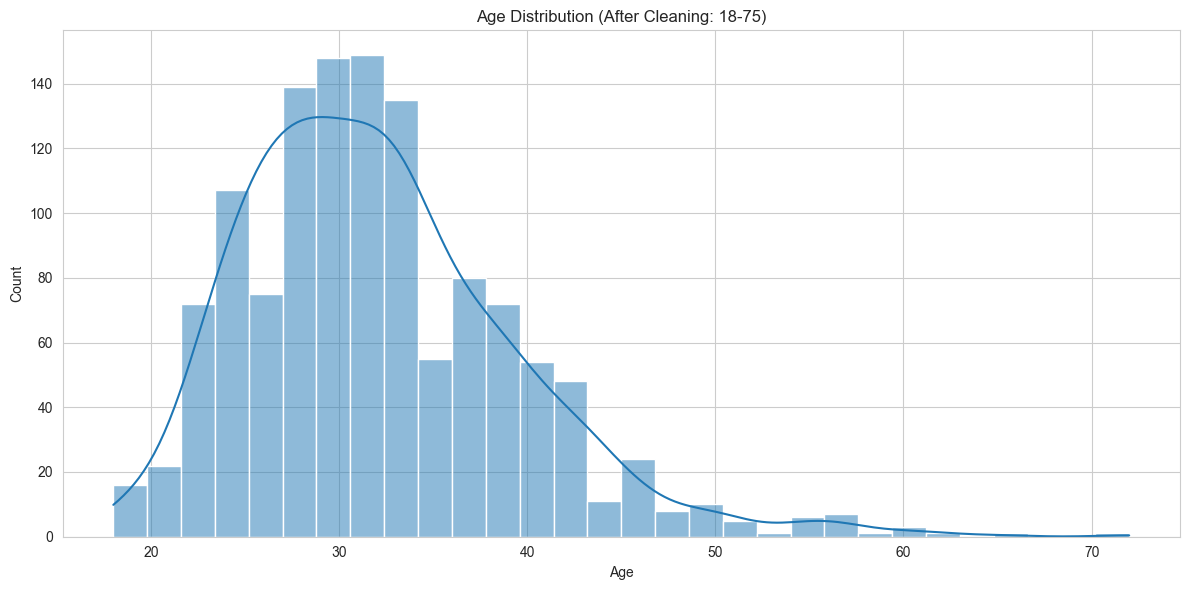

Removed 8 rows with invalid ages
Age Statistics (Cleaned):
count    1251.000000
mean       32.076739
std         7.288272
min        18.000000
25%        27.000000
50%        31.000000
75%        36.000000
max        72.000000
Name: Age, dtype: float64


In [7]:
# Filter ages between 18 and 75
df_age_cleaned = df[(df['Age'] >= 18) & (df['Age'] <= 75)]

# Plot age distribution after cleaning
fig, ax = plt.subplots(figsize=(12, 6))
sns.histplot(df_age_cleaned['Age'], bins=30, kde=True, ax=ax)
ax.set_xlabel('Age')
ax.set_ylabel('Count')
ax.set_title('Age Distribution (After Cleaning: 18-75)')
plt.tight_layout()

# Save figure
save_figure(fig, 'age_distribution_after_cleaning', output_dir='../outputs/figures')
plt.show()

print(f"Removed {len(df) - len(df_age_cleaned)} rows with invalid ages")
print(f"Age Statistics (Cleaned):")
print(df_age_cleaned['Age'].describe())

## Gender Value Counts (Exposing Messy Values)

In [8]:
# Display gender value counts to show messy values
print("Gender Value Counts (Raw Data):")
print(df['Gender'].value_counts())
print(f"\nNumber of unique gender values: {df['Gender'].nunique()}")

Gender Value Counts (Raw Data):
Gender
Male                                              615
male                                              206
Female                                            121
M                                                 116
female                                             62
F                                                  38
m                                                  34
f                                                  15
Make                                                4
Male                                                3
Woman                                               3
Cis Male                                            2
Man                                                 2
Female (trans)                                      2
Female                                              2
Trans woman                                         1
msle                                                1
male leaning androgynous                   

## Class Balance: Treatment

Saved figure to ../outputs/figures\class_balance_treatment.png


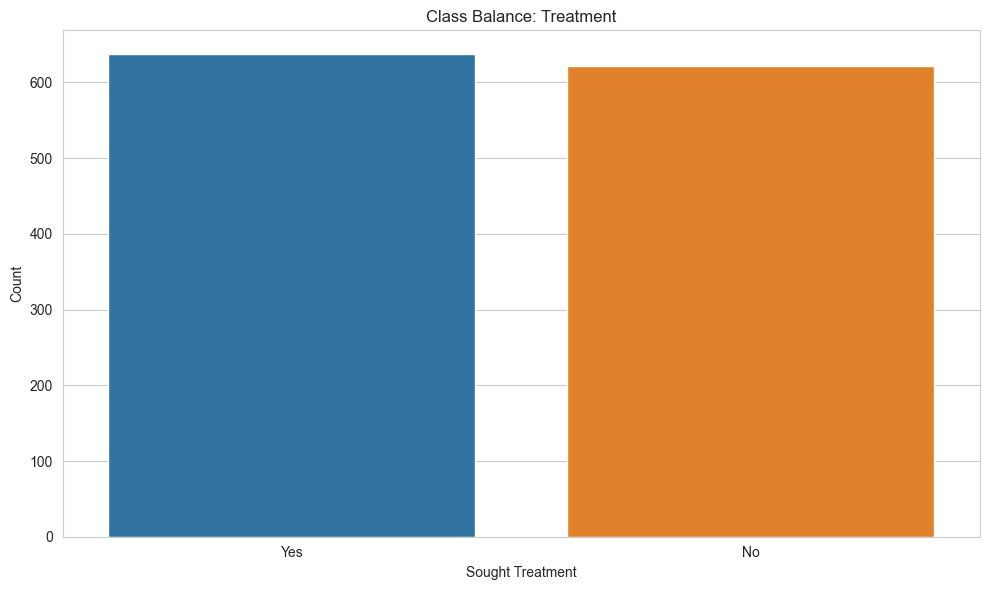

Treatment Distribution:
treatment
Yes    50.595711
No     49.404289
Name: proportion, dtype: float64


In [9]:
# Plot class balance for treatment
fig, ax = plt.subplots(figsize=(10, 6))
sns.countplot(data=df, x='treatment', ax=ax)
ax.set_xlabel('Sought Treatment')
ax.set_ylabel('Count')
ax.set_title('Class Balance: Treatment')
plt.tight_layout()

# Save figure
save_figure(fig, 'class_balance_treatment', output_dir='../outputs/figures')
plt.show()

print("Treatment Distribution:")
print(df['treatment'].value_counts(normalize=True) * 100)

## Class Balance: Mental Health Consequence

Saved figure to ../outputs/figures\class_balance_mental_health_consequence.png


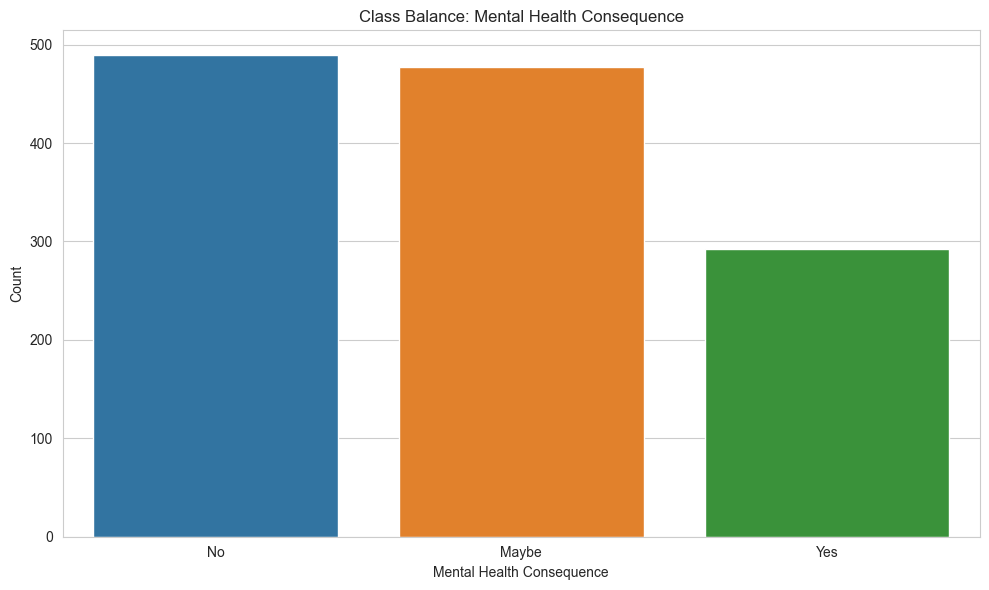

Mental Health Consequence Distribution:
mental_health_consequence
No       38.919778
Maybe    37.887212
Yes      23.193010
Name: proportion, dtype: float64


In [10]:
# Plot class balance for mental_health_consequence
fig, ax = plt.subplots(figsize=(10, 6))
sns.countplot(data=df, x='mental_health_consequence', ax=ax)
ax.set_xlabel('Mental Health Consequence')
ax.set_ylabel('Count')
ax.set_title('Class Balance: Mental Health Consequence')
plt.tight_layout()

# Save figure
save_figure(fig, 'class_balance_mental_health_consequence', output_dir='../outputs/figures')
plt.show()

print("Mental Health Consequence Distribution:")
print(df['mental_health_consequence'].value_counts(normalize=True) * 100)

## Correlation Heatmap (Encoded Columns)

Saved figure to ../outputs/figures\correlation_heatmap.png


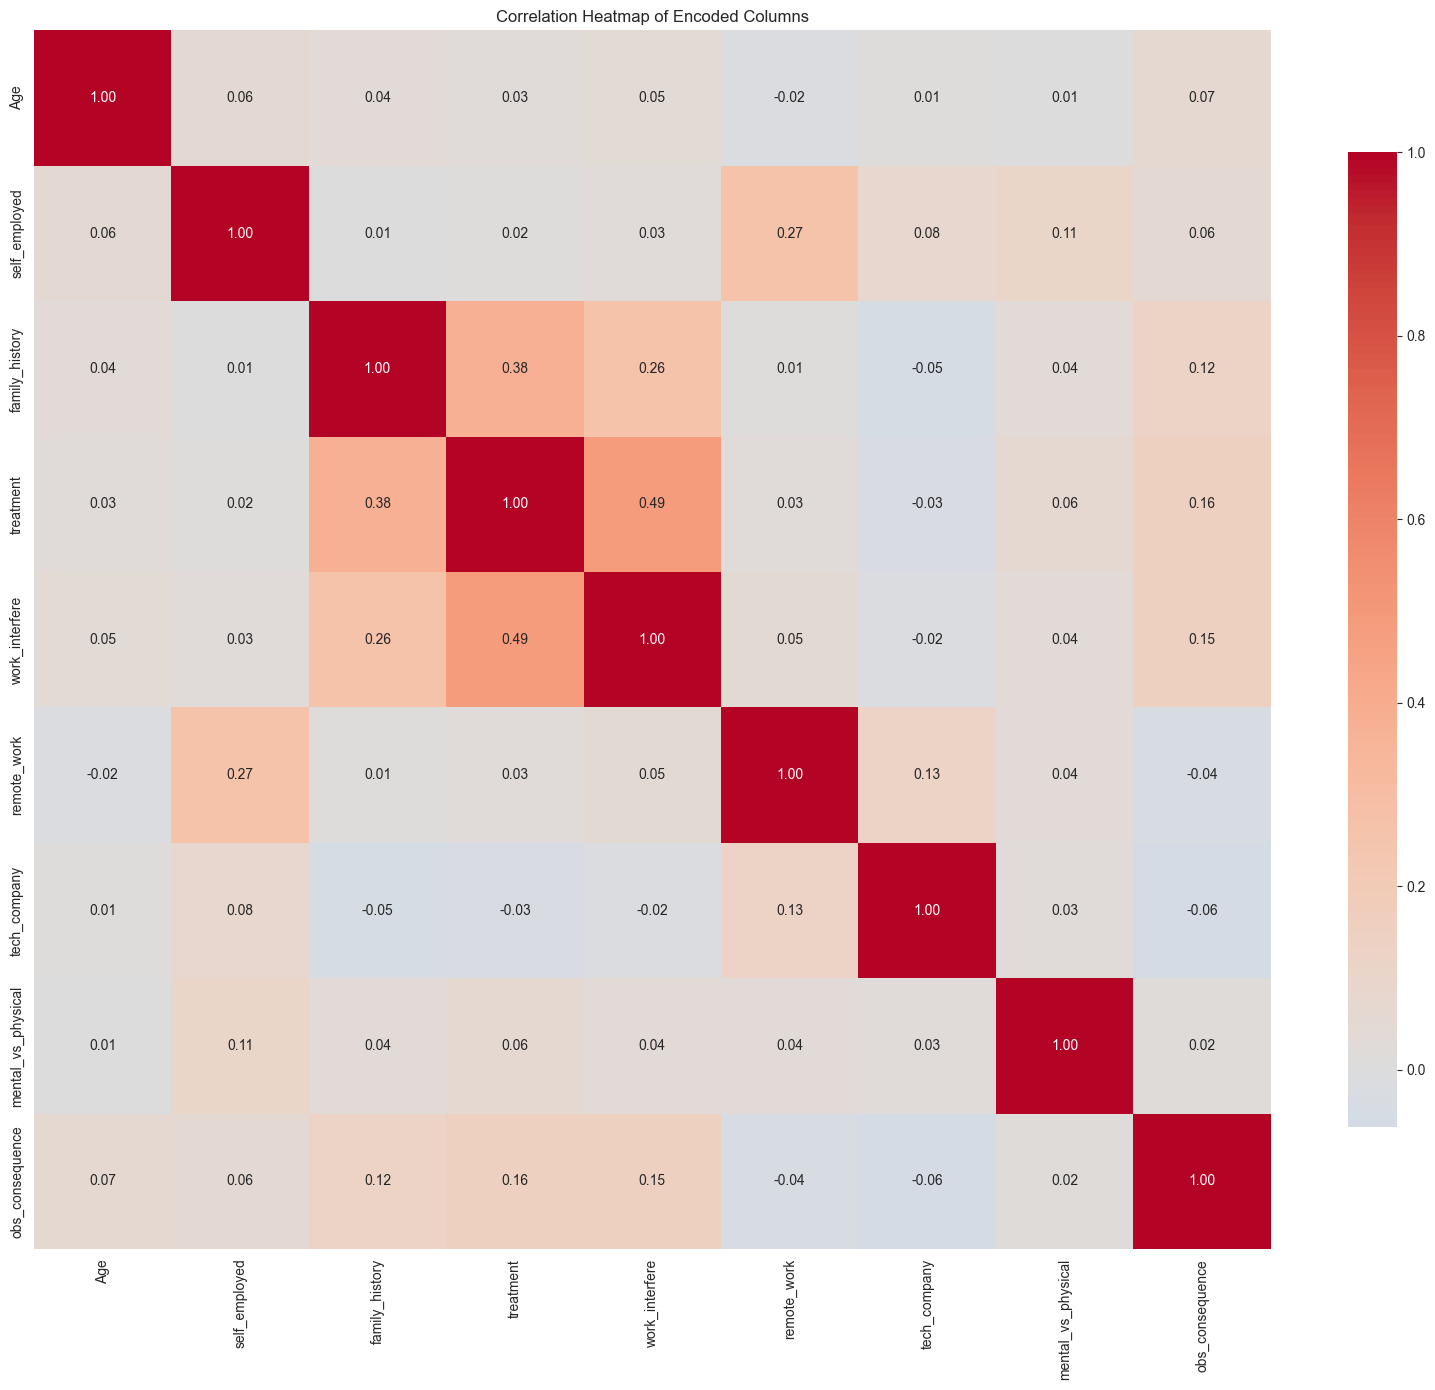

In [11]:
# Create a copy for encoding
df_encoded = df.copy()

# Encode binary columns for correlation
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

binary_cols = ['treatment', 'remote_work', 'tech_company', 'self_employed', 
              'family_history', 'mental_vs_physical', 'obs_consequence']

for col in binary_cols:
    if col in df_encoded.columns:
        df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))

# Encode ordinal columns
work_interfere_map = {'Never': 0, 'Rarely': 1, 'Sometimes': 2, 'Often': 3, "Don't know": -1}
if 'work_interfere' in df_encoded.columns:
    df_encoded['work_interfere'] = df_encoded['work_interfere'].map(work_interfere_map)

# Calculate correlation matrix for numeric columns
numeric_cols = df_encoded.select_dtypes(include=[np.number]).columns
correlation_matrix = df_encoded[numeric_cols].corr()

# Plot correlation heatmap
fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Correlation Heatmap of Encoded Columns')
plt.tight_layout()

# Save figure
save_figure(fig, 'correlation_heatmap', output_dir='../outputs/figures')
plt.show()

## Work Interfere vs Treatment

Saved figure to ../outputs/figures\work_interfere_vs_treatment.png


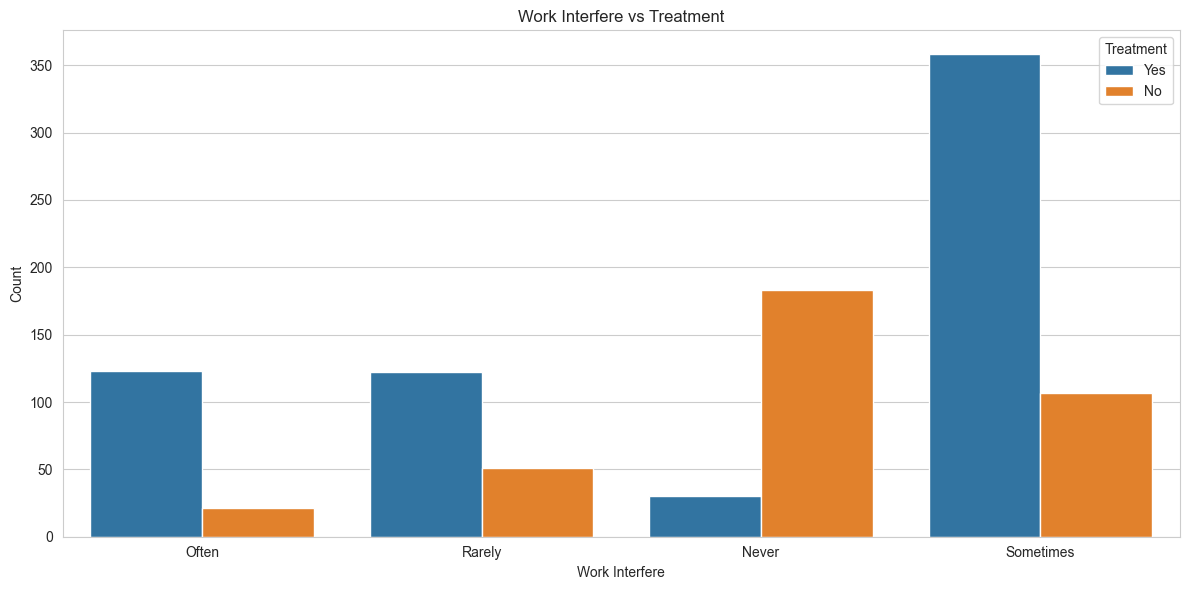

In [12]:
# Bar chart: work_interfere vs treatment
fig, ax = plt.subplots(figsize=(12, 6))
sns.countplot(data=df, x='work_interfere', hue='treatment', ax=ax)
ax.set_xlabel('Work Interfere')
ax.set_ylabel('Count')
ax.set_title('Work Interfere vs Treatment')
ax.legend(title='Treatment')
plt.tight_layout()

# Save figure
save_figure(fig, 'work_interfere_vs_treatment', output_dir='../outputs/figures')
plt.show()

## Family History vs Treatment

Saved figure to ../outputs/figures\family_history_vs_treatment.png


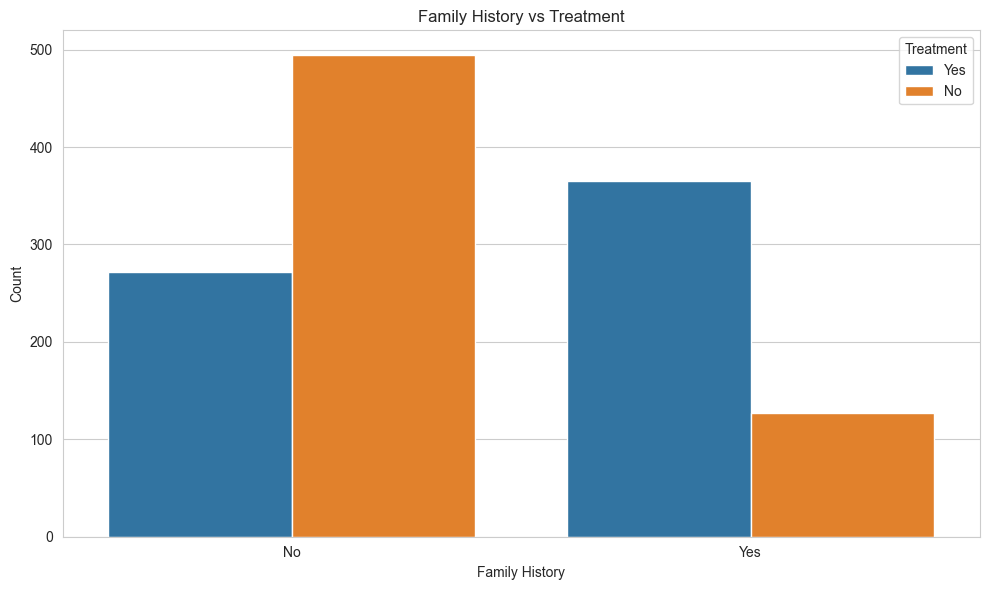

In [13]:
# Bar chart: family_history vs treatment
fig, ax = plt.subplots(figsize=(10, 6))
sns.countplot(data=df, x='family_history', hue='treatment', ax=ax)
ax.set_xlabel('Family History')
ax.set_ylabel('Count')
ax.set_title('Family History vs Treatment')
ax.legend(title='Treatment')
plt.tight_layout()

# Save figure
save_figure(fig, 'family_history_vs_treatment', output_dir='../outputs/figures')
plt.show()

## Number of Employees vs Treatment

Saved figure to ../outputs/figures\no_employees_vs_treatment.png


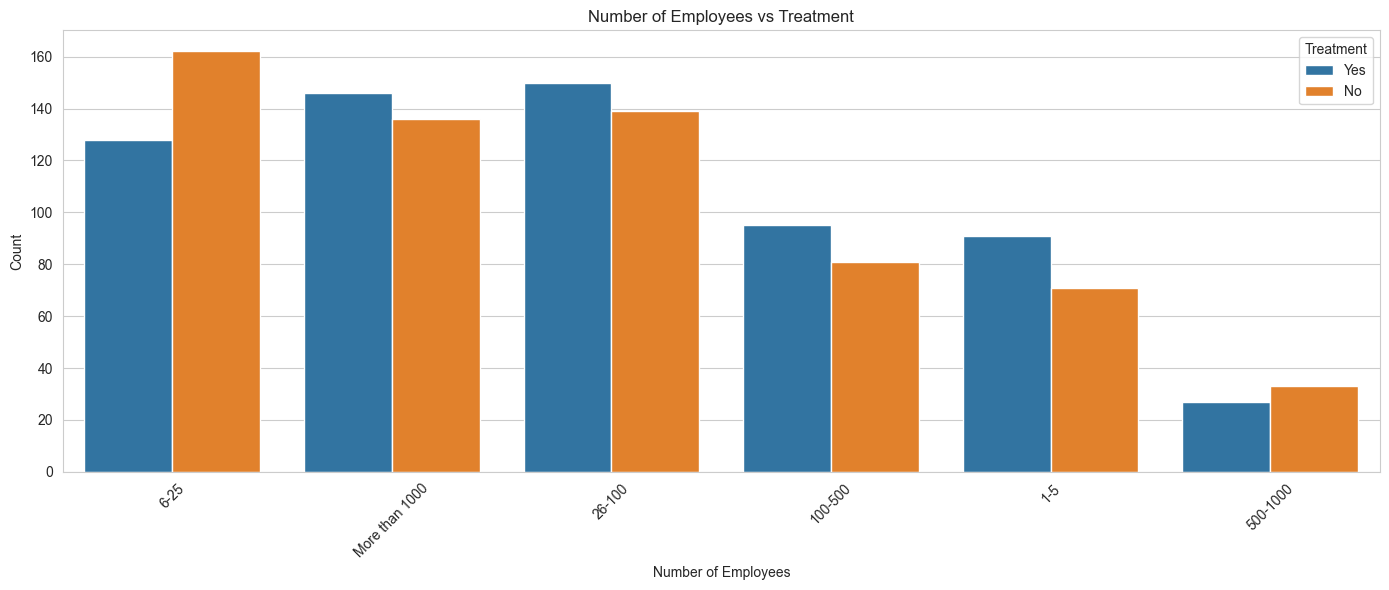

In [14]:
# Bar chart: no_employees vs treatment
fig, ax = plt.subplots(figsize=(14, 6))
sns.countplot(data=df, x='no_employees', hue='treatment', ax=ax)
ax.set_xlabel('Number of Employees')
ax.set_ylabel('Count')
ax.set_title('Number of Employees vs Treatment')
ax.legend(title='Treatment')
plt.xticks(rotation=45)
plt.tight_layout()

# Save figure
save_figure(fig, 'no_employees_vs_treatment', output_dir='../outputs/figures')
plt.show()

## Remote Work vs Treatment

Saved figure to ../outputs/figures\remote_work_vs_treatment.png


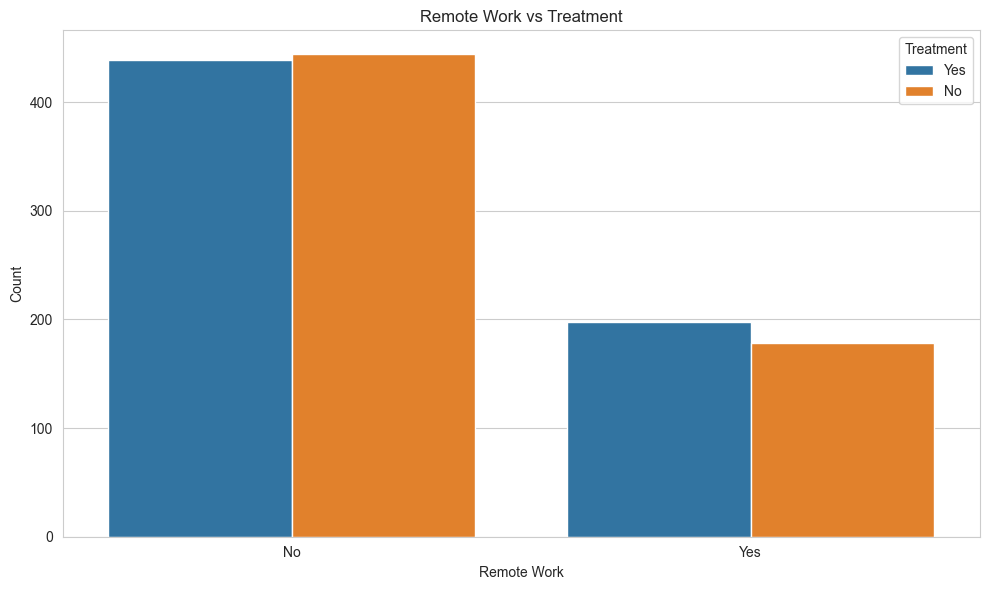

In [15]:
# Count plot: remote_work vs treatment
fig, ax = plt.subplots(figsize=(10, 6))
sns.countplot(data=df, x='remote_work', hue='treatment', ax=ax)
ax.set_xlabel('Remote Work')
ax.set_ylabel('Count')
ax.set_title('Remote Work vs Treatment')
ax.legend(title='Treatment')
plt.tight_layout()

# Save figure
save_figure(fig, 'remote_work_vs_treatment', output_dir='../outputs/figures')
plt.show()

## Tech Company vs Treatment

Saved figure to ../outputs/figures\tech_company_vs_treatment.png


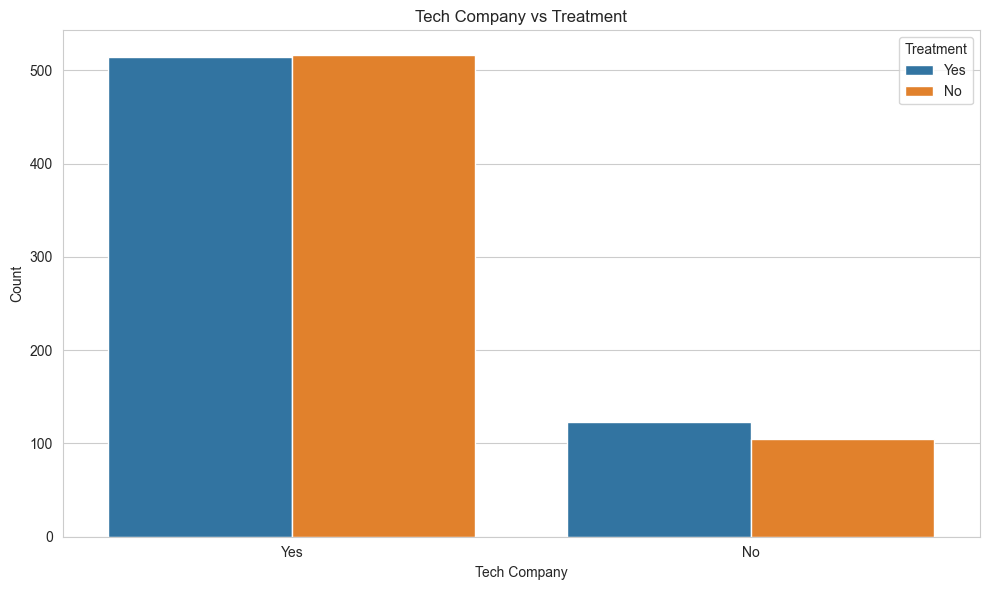

In [16]:
# Count plot: tech_company vs treatment
fig, ax = plt.subplots(figsize=(10, 6))
sns.countplot(data=df, x='tech_company', hue='treatment', ax=ax)
ax.set_xlabel('Tech Company')
ax.set_ylabel('Count')
ax.set_title('Tech Company vs Treatment')
ax.legend(title='Treatment')
plt.tight_layout()

# Save figure
save_figure(fig, 'tech_company_vs_treatment', output_dir='../outputs/figures')
plt.show()

## Summary of EDA Findings

In [17]:
print("="*60)
print("EDA SUMMARY")
print("="*60)
print(f"\n1. Dataset Shape: {df.shape}")
print(f"2. Total Missing Values: {df.isnull().sum().sum()}")
print(f"3. Age Range: {df['Age'].min()} to {df['Age'].max()} (after cleaning: 18-75)")
print(f"4. Unique Gender Values: {df['Gender'].nunique()} (needs cleaning)")
print(f"5. Treatment Class Balance: {df['treatment'].value_counts().to_dict()}")
print(f"6. Mental Health Consequence Classes: {df['mental_health_consequence'].nunique()}")
print("\nKey Observations:")
print("- Age column contains outliers (negative values, very high ages)")
print("- Gender column has many inconsistent values that need standardization")
print("- Missing values present in self_employed, work_interfere, and other columns")
print("- Treatment target is relatively balanced")
print("- Strong correlations observed between some workplace perception variables")
print("="*60)

EDA SUMMARY

1. Dataset Shape: (1259, 27)
2. Total Missing Values: 1892
3. Age Range: -1726 to 99999999999 (after cleaning: 18-75)
4. Unique Gender Values: 49 (needs cleaning)
5. Treatment Class Balance: {'Yes': 637, 'No': 622}
6. Mental Health Consequence Classes: 3

Key Observations:
- Age column contains outliers (negative values, very high ages)
- Gender column has many inconsistent values that need standardization
- Missing values present in self_employed, work_interfere, and other columns
- Treatment target is relatively balanced
- Strong correlations observed between some workplace perception variables
